# **Travaux pratiques : analyse des données de churn**

In [33]:
# Lire le fichier csv

import pandas as pd

dataset = pd.read_csv('customer_churn.csv')
dataset.head()

,Names,Age,Total_Purchase,Account_Manager,Years,Num_Sites,Onboard_date,Location,Company,Churn
0,Cameron Williams,42.0,11066.80,0,7.22,8.0,2013-08-30 07:00:40,"10265 Elizabeth Mission Barkerburgh, AK 89518",Harvey LLC,1
1,Kevin Mueller,41.0,11916.22,0,6.50,11.0,2013-08-13 00:38:46,"6157 Frank Gardens Suite 019 Carloshaven, RI 1...",Wilson PLC,1
2,Eric Lozano,38.0,12884.75,0,6.67,12.0,2016-06-29 06:20:07,"1331 Keith Court Alyssahaven, DE 90114","Miller, Johnson and Wallace",1
3,Phillip White,42.0,8010.76,0,6.71,10.0,2014-04-22 12:43:12,"13120 Daniel Mount Angelabury, WY 30645-4695",Smith Inc,1
4,Cynthia Norton,37.0,9191.58,0,5.56,9.0,2016-01-19 15:31:15,"765 Tricia Row Karenshire, MH 71730",Love-Jones,1


In [34]:
# Descriptif du fichier

dataset.describe()

,Age,Total_Purchase,Account_Manager,Years,Num_Sites,Churn
count,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000
mean,41.816667,10062.824033,0.481111,5.273156,8.587778,0.166667
std,6.127560,2408.644532,0.499921,1.274449,1.764836,0.372885
min,22.000000,100.000000,0.000000,1.000000,3.000000,0.000000
25%,38.000000,8497.122500,0.000000,4.450000,7.000000,0.000000
50%,42.000000,10045.870000,0.000000,5.215000,8.000000,0.000000
75%,46.000000,11760.105000,1.000000,6.110000,10.000000,0.000000
max,65.000000,18026.010000,1.000000,9.150000,14.000000,1.000000


In [35]:
# Afficher les noms des colonnes

list(dataset.columns)

['Names',
 'Age',
 'Total_Purchase',
 'Account_Manager',
 'Years',
 'Num_Sites',
 'Onboard_date',
 'Location',
 'Company',
 'Churn']

In [36]:
# Afficher la colonne Nom

dataset['Names']

,Names
0,Cameron Williams
1,Kevin Mueller
2,Eric Lozano
3,Phillip White
4,Cynthia Norton
...,...
895,Paul Miller
896,Natalie Hodges
897,Ana Smith
898,Justin Leonard


In [37]:
# Ecxtraire le nom et l'âge

dataset[['Names', 'Age']]

,Names,Age
0,Cameron Williams,42.0
1,Kevin Mueller,41.0
2,Eric Lozano,38.0
3,Phillip White,42.0
4,Cynthia Norton,37.0
...,...,...
895,Paul Miller,42.0
896,Natalie Hodges,52.0
897,Ana Smith,45.0
898,Justin Leonard,51.0


In [38]:
# Rechercher le quatrième éléments de la colonne Names

dataset.at[3, 'Names']

'Phillip White'

In [39]:
# Supprimer les colonnes Names, Company, Location et Onboard date

dataset.drop(['Names', 'Company', 'Location', 'Onboard_date'], axis=1, inplace=True)
dataset.head()

,Age,Total_Purchase,Account_Manager,Years,Num_Sites,Churn
0,42.0,11066.80,0,7.22,8.0,1
1,41.0,11916.22,0,6.50,11.0,1
2,38.0,12884.75,0,6.67,12.0,1
3,42.0,8010.76,0,6.71,10.0,1
4,37.0,9191.58,0,5.56,9.0,1


In [40]:
# Sélectionner les lignes telles que l'âge est supérieur à 40

dataset[dataset['Age'] > 40].head()

,Age,Total_Purchase,Account_Manager,Years,Num_Sites,Churn
0,42.0,11066.80,0,7.22,8.0,1
1,41.0,11916.22,0,6.50,11.0,1
3,42.0,8010.76,0,6.71,10.0,1
5,48.0,10356.02,0,5.12,8.0,1
6,44.0,11331.58,1,5.23,11.0,1


In [41]:
# Sélectionner les churneurs

dataset[dataset['Churn'] == 1].head()

,Age,Total_Purchase,Account_Manager,Years,Num_Sites,Churn
0,42.0,11066.80,0,7.22,8.0,1
1,41.0,11916.22,0,6.50,11.0,1
2,38.0,12884.75,0,6.67,12.0,1
3,42.0,8010.76,0,6.71,10.0,1
4,37.0,9191.58,0,5.56,9.0,1


In [42]:
# Sélectionner les churneurs dont l'âge est supérieur à 40

dataset[(dataset['Churn'] == 1) & (dataset['Age'] > 40)].head()

,Age,Total_Purchase,Account_Manager,Years,Num_Sites,Churn
0,42.0,11066.80,0,7.22,8.0,1
1,41.0,11916.22,0,6.50,11.0,1
3,42.0,8010.76,0,6.71,10.0,1
5,48.0,10356.02,0,5.12,8.0,1
6,44.0,11331.58,1,5.23,11.0,1


## Statistiques descriptives

In [43]:
# Calculer la moyenne de l'âge

dataset['Age'].mean()

np.float64(41.81666666666667)

In [44]:
# Calculer la moyenne de l'âge pour les churneurs

dataset[dataset['Churn'] == 1]['Age'].mean()

np.float64(42.99333333333333)

In [45]:
# Calculer la moyenne de l'âge pour les non churneurs

dataset[dataset['Churn'] == 0]['Age'].mean()


np.float64(41.58133333333333)

In [46]:
# Calculer la moyenne de l'âge par modalité du churn

dataset.groupby('Churn')['Age'].mean()

,Age
Churn,
0,41.581333
1,42.993333


In [47]:
# Calculer la moyenne de l'âge et years par modalité du churn

dataset.groupby('Churn')[['Age', 'Years']].mean().round()

,Age,Years
Churn,,
0,42.0,5.0
1,43.0,6.0


## Visualisation des données

In [48]:
# Importer matplotlib et seaborn

import matplotlib.pyplot as plt
import seaborn as sns

<Axes: xlabel='Churn', ylabel='count'>

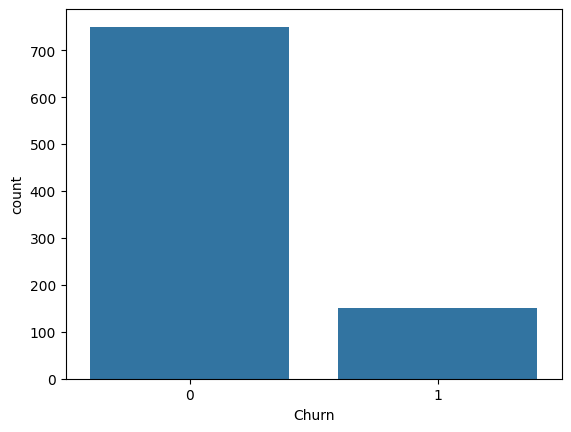

In [49]:
# Visualiser la variable churn

sns.countplot(x='Churn', data=dataset)

<Axes: xlabel='Churn', ylabel='Age'>

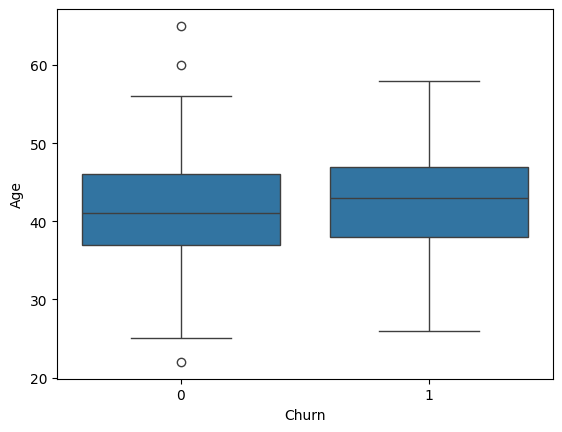

In [50]:
# Visualiser le churn en fonction de l'âge

sns.boxplot(x='Churn', y='Age', data=dataset)

<Axes: xlabel='Age', ylabel='Density'>

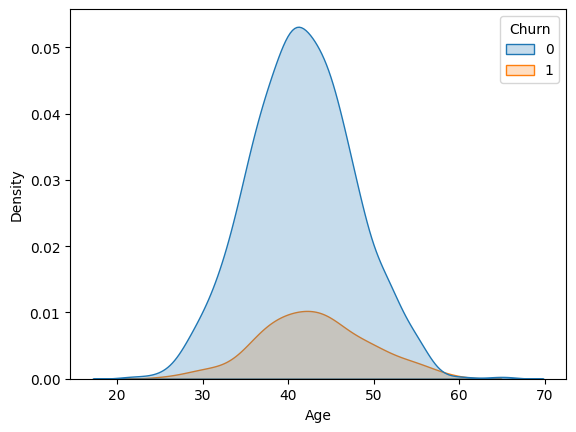

In [51]:
# Visualiser le churn en fonction de l'âge sous forme de densité

sns.kdeplot(x='Age', hue='Churn', data=dataset, fill=True)

<Axes: xlabel='Churn', ylabel='Total_Purchase'>

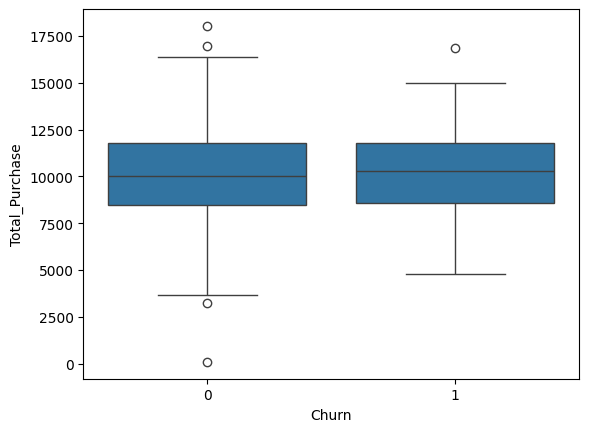

In [52]:
# Visualiser le churn en fonction de total purchase

sns.boxplot(x='Churn', y='Total_Purchase', data=dataset)

<Axes: xlabel='Total_Purchase', ylabel='Density'>

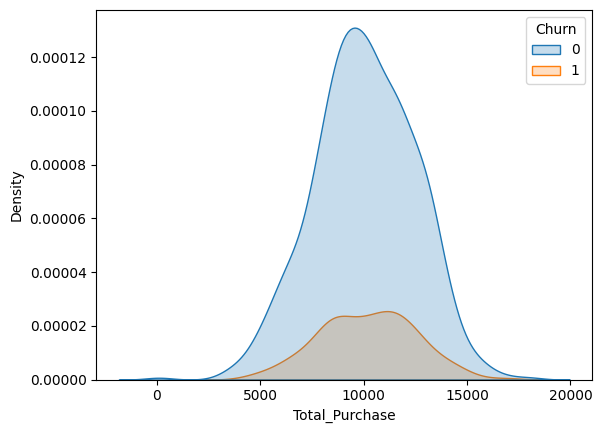

In [53]:
# Visualiser le churn en fonction de total purchadse sous forme de densité

sns.kdeplot(x='Total_Purchase', hue='Churn', data=dataset, fill=True)

<Axes: xlabel='Churn', ylabel='Years'>

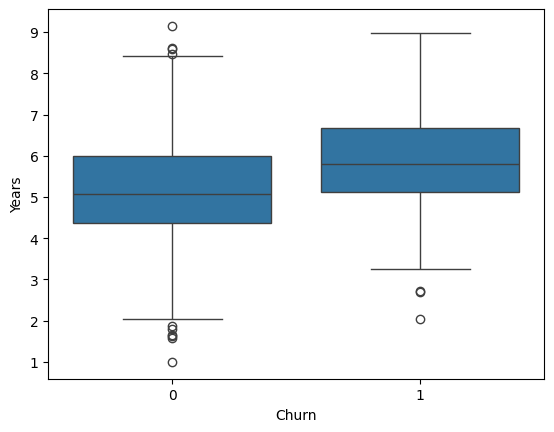

In [54]:
# Visualiser le churn en fonction de Years

sns.boxplot(x='Churn', y='Years', data=dataset)

<Axes: xlabel='Churn', ylabel='Num_Sites'>

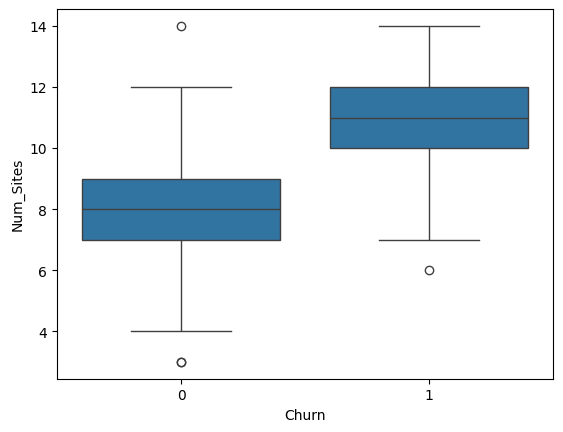

In [55]:
# Visualiser le churn en fonction de Num_Sites

sns.boxplot(x='Churn', y='Num_Sites', data=dataset)

<Axes: xlabel='Num_Sites', ylabel='Density'>

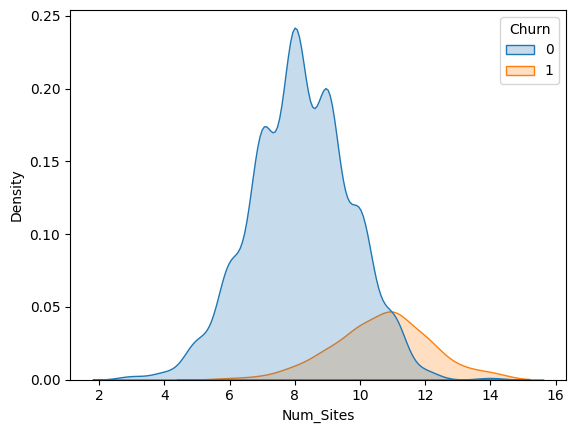

In [56]:
# Visualiser le churn en fonction de Num_Sites sous forme de densité

sns.kdeplot(x='Num_Sites', hue='Churn', data=dataset, fill=True)

<Axes: xlabel='Churn', ylabel='count'>

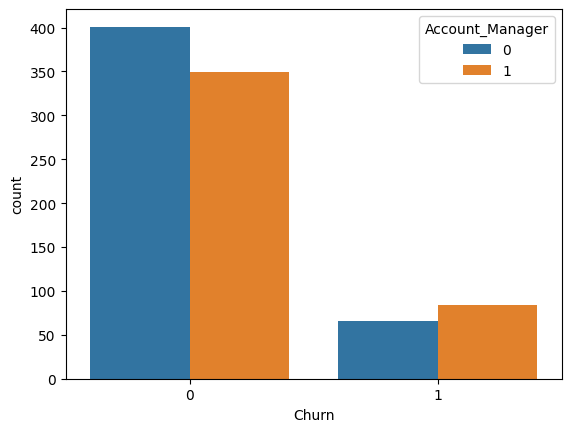

In [57]:
# Visualiser le churn en fonction de Account Manager

sns.countplot(x='Churn', hue='Account_Manager', data=dataset)

<Axes: xlabel='Age', ylabel='Years'>

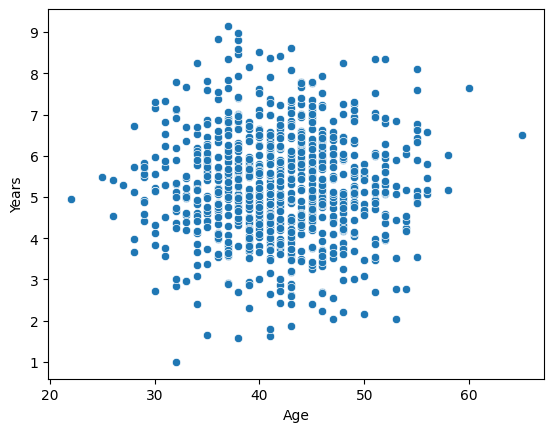

In [58]:
# Visualiser Years en fonction de l'âge

sns.scatterplot(x='Age', y='Years', data=dataset)

<Axes: xlabel='Churn', ylabel='Age'>

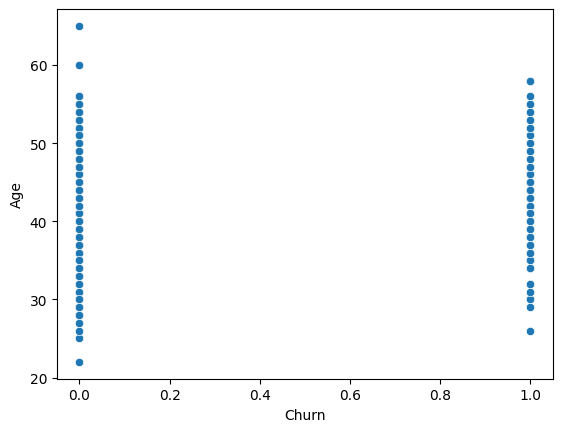

In [65]:

# Visualiser le churn en fonction de l'âge

sns.scatterplot(x='Churn', y='Age', data=dataset)